In [4]:
import numpy as np
from numpy import linalg 
from random import randint
import matplotlib.pyplot as plt

Au siÈcle des lumières, on jouait beaucoup à un jeu de hasard appelé jeu de treize, consistant à faire
des paris sur une rencontre , c'est-à-dire une carte identiquement placée dans deux jeux identiques mais mélangés au hasard. L'usage  était de parier à  7 contre 12 sur une rencontre (deux
cartes identiques dans les deux jeux). Euler explique d'où
vient ce 7 contre 12 dans l'article : Calcul
de la probabilité du jeu de rencontres publié en $1741$. Il est a noter qu' Euler montre cette probabilité
pour un nombre de cartes $n$ quelconque (pas seulement 13)


\maketitle

Dans son célèbre mémoire intitulé \textit{Calcul de la probabilité dans le jeu de rencontre} (référencé sous le numéro \textbf{E201} dans les archives d'Euler), \textbf{Leonhard Euler} a démontré que pour un nombre quelconque $n$ de cartes, les probabilités du jeu obéissent à des lois combinatoires remarquables.

## Formules Générales pour $n$ Cartes

La probabilité d'obtenir \textbf{au moins une rencontre} (c'est-à-dire de gagner le jeu) est donnée par la formule :
$$
P(\text{Gagner}) = 1 - \frac{1}{2!} + \frac{1}{3!} - \frac{1}{4!} + \dots + \frac{(-1)^{n-1}}{n!} = \sum_{k=1}^n \frac{(-1)^{k-1}}{k!}
$$

À l'inverse, la probabilité qu'\textbf{aucune rencontre} ne se produise (ce que l'on appelle un \textbf{dérangement} en combinatoire, noté $D_n$) est :
$$
P(\text{Perdre}) = 1 - 1 + \frac{1}{2!} - \frac{1}{3!} + \dots + \frac{(-1)^n}{n!} = \sum_{k=0}^n \frac{(-1)^k}{k!}
$$

## Convergence vers le nombre $e$

L'un des résultats les plus remarquables mis en évidence par Euler est que cette probabilité se stabilise de manière extrêmement rapide lorsque $n$ grandit. En faisant tendre $n$ vers l'infini, on reconnaît le développement en série de l'exponentielle ($e^{-1}$) :
\textbf{Limite de perte :} $\displaystyle \lim_{n \to \infty} P(\text{Perdre}) = \frac{1}{e} \approx \mathbf{0{,}3679}$ (soit 36,79 \% de chances).
   \textbf{Limite de gain :} $\displaystyle \lim_{n \to \infty} P(\text{Gagner}) = 1 - \frac{1}{e} \approx \mathbf{0{,}6321}$ (soit 63,21 \% de chances).


Dès que $n \ge 5$, la probabilité ne varie presque plus. Que vous jouiez avec \textbf{13 cartes} (le traditionnel \textit{jeu de treize}) ou avec un jeu complet de \textbf{52 cartes}, vos chances de gagner restent virtuellement identiques à \textbf{63,2 \%}.

## La Méthode de Récurrence d'Euler

### quations de récurrence :

 Soit $D_n$ le nombre de configurations sans aucune rencontre pour $n$ cartes.  Euler démontre la relation suivante pour construire le problème de proche en proche :
   $$
    D_n = (n-1)(D_{n-1} + D_{n-2})
    $$
   En transformant cette récurrence, il obtient une formule itérative simple : 
    $$
    D_n = nD_{n-1} + (-1)^n
   $$
    Il en déduit la formule exacte de $D_n$, qu'il lui suffit ensuite de diviser par le nombre total de permutations possibles ($n!$) pour obtenir la probabilité.




 Proposer une fonction jeu de rencontre qui prend en argument $n$ et renvoie $1$ si il y a une
rencontre dans un jeu à $n$ cartes et $0$ sinon.
  Vérifier que l'on aurait pu conjecturer les probabilité trouvées par Euler.


In [1]:
from math import factorial
def formule1(n):
  S = 0.0
  for k in range(n + 1):
      S += ((-1) ** k) / factorial(k)
  return S

In [4]:
import random as rd
import matplotlib.pyplot as plt
import numpy as np
def bernoulli(p):
    if rd.random() < p:
        return 1
    else:
        return 0
def rencontre(n):
    pass
 
def main():
  N=10000 
  n=13
  V1 = [rencontre(n) for _ in range(N)]
  p= V1.count(1)/N 
  print('proba simulée pour que le pemir joueur gagn est', p)
  print('le rapport simulé', (1-p)/p)
  print('ple rapport théoique', 7./12.)
  print('ple rapport théoiqueVRAI', 1-formule1(n))  
 
main()  

proba simulée pour que le pemir joueur gagn est 0.6319
le rapport simulé 0.582528881152081
ple rapport théoique 0.5833333333333334
ple rapport théoiqueVRAI 0.6321205588393087


# Paradoxe  d'anniverssaire
Dans une classe de $n$  élèves quelle est la probabilité que deux personnes aient leur anniversaire le
même jour?
On fera l'hypothèse qu'une anné dure $365$ jours.
-Proposer un modélisation de ce problème pour répondre à la question.
- Conjecturer le nombre élèves nécessaire pour que la probabilité tombe à $50\%$. à  à $99\%$
- Expliquer pourquoi on appelle ce problème le paradoxe des anniversaires .
- Déterminer la probabilité exacte qu'au moins deux personnes aient le même anniversaire.
- On note $A_n$ l'événement :
$
A_n=\{\text{au moins deux personnes ont le même anniversaire}\}.
$

- Déterminer la probabilité exacte $p_n=P(A_n)$.
- Montrer que
$
p_n=1-\prod_{k=0}^{n-1}\left(1-\frac{k}{365}\right).
$
- Calculer la probabilité pour $n=23$.
- Montrer que, lorsque $n\ll365$,
$
p_n\approx 1-\exp\left(-\frac{n(n-1)}{730}\right).
$
- Vérifier ce résultat par simulation Monte-Carlo.
- Construire un intervalle de confiance à 95\%.

# Démonstration 

$
A_n^c=\{\text{tous les anniversaires sont distincts}\}.
$

La première personne peut choisir n'importe quelle date.

La deuxième doit éviter l'anniversaire de la première :
$
\frac{364}{365}.
$

La troisième doit éviter les deux dates déjà choisies :
$
\frac{363}{365}.
$

En poursuivant ce raisonnement, on obtient
$
P(A_n^c)=\prod_{k=0}^{n-1}\frac{365-k}{365}.
$

Par complémentarité,
$
p_n=P(A_n)=1-P(A_n^c).
$

Donc
$$
\boxed{p_n=1-\prod_{k=0}^{n-1}\frac{365-k}{365}}.
$$

$
\ln P(A_n^c)
\approx -\frac1{365}\sum_{k=0}^{n-1}k.
$

Or
$
\sum_{k=0}^{n-1}k=\frac{n(n-1)}2.
$

Donc
$
\ln P(A_n^c)
\approx -\frac{n(n-1)}{730}.
$

En exponentiant,
$
P(A_n^c)
\approx
\exp\left(-\frac{n(n-1)}{730}\right).
$

Finalement,
$$
\boxed{
p_n\approx 1-\exp\left(-\frac{n(n-1)}{730}\right)
}
$$

## Cas particulier $n=23$ 

$
p_{23}=1-\prod_{k=0}^{22}\frac{365-k}{365}.
$

Numériquement,
$
p_{23}\approx0.507297.
$

Ainsi,
$$
\boxed{p_{23}\approx50.73\%}
$$

## Détermination du seuil de 50\%

$
1-\exp\left(-\frac{n(n-1)}{730}\right)=0.5.
$


La solution positive est
$
n\approx22.99.
$

Le plus petit entier satisfaisant cette condition est donc
$$
\boxed{n=23}.
$$

In [1]:
import numpy as np

def simulation(n,N=100000):
    pass

print(simulation(23))

0.50821


# Intervalle de confiance

Soit
$
\widehat p_N=\frac1N\sum_{i=1}^{N}X_i,
$
avec
$
X_i=\mathbf 1_{A_n}.
$

Par le théorème central limite,
$
\widehat p_N
\approx
\mathcal N\left(p,\frac{p(1-p)}N\right).
$

Un intervalle de confiance à 95\% est
$$
\boxed{
\widehat p_N
\pm
1.96\sqrt{\frac{\widehat p_N(1-\widehat p_N)}N}
}
$$

Expliction : Si l'on répète un très grand nombre de fois l'expérience complète de simulation et que l'on construit un intervalle de confiance à chaque répétition, alors environ $95\%$ des intervalles obtenus contiendront la vraie probabilité $p$.

Supposons que l'on réalise$ N=10000 $ simulations et que l'on obtienne $ \widehat p_N=0.512. $ 

L'erreur standard vaut $ SE = \sqrt{ \frac{0.512(1-0.512)} {10000} } = 0.004998.$
La marge d'erreur est $ 1.96\times SE = 0.00980. $ 
L'intervalle de confiance à 95\% est donc $ [0.512-0.00980,\; 0.512+0.00980]. $ 

Ainsi, $ \boxed{ IC_{95\%} = [0.5022,\;0.5218] } $
La valeur théorique $ p_{23}=0.507297 $ appartient bien à cet intervalle, ce qui confirme la validité de la simulation.

In [2]:
import random as rd
import matplotlib.pyplot as plt
import numpy as np
import math 
# On simule d'abord une classe.
def classeanniversaire(n):
   pass
# Conjecture du nombre d'élèves pour avoir p% de chance
# N est le nombre d'élève et p la proba souhaitée
def conjectureleves(N, p):
    pass
 
def main():
  N=100 
  #n=45
  p=0.94
 # "" probabilté théorique : 1- 365!/(365-n)!*1/365^n""
 #voir https://fr.wikipedia.org/wiki/Paradoxe_des_anniversaires
  #V1 = [classe_anniversaire(n) for _ in range(N)]
  #p= V1.count(1)/N 
  #print('proba simulée pour une clase de ',n,'élève est ', p)
  #print('probabilté théorique est', math.factorial(365)/math.factorial(365-n)*1/
      #  1/365**n)
  n=conjectureleves(N, p)
  print('nombre délève', n)
  
 
main()  

nombre délève 43


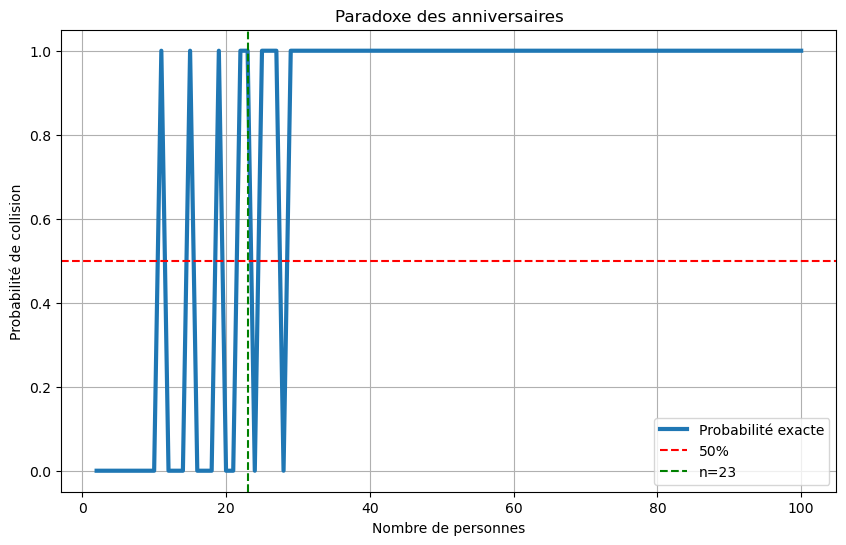

In [25]:
import numpy as np
import matplotlib.pyplot as plt

x=np.arange(2,101)
y=[classe_anniversaire(k) for k in x]

plt.figure(figsize=(10,6))
plt.plot(x,y,lw=3,label='Probabilité exacte')
plt.axhline(0.5,color='red',ls='--',label='50%')
plt.axvline(23,color='green',ls='--',label='n=23')
plt.xlabel('Nombre de personnes')
plt.ylabel('Probabilité de collision')
plt.title('Paradoxe des anniversaires')
plt.grid(True)
plt.legend()
plt.show()


# Jeu de portes
On considère le jeu suivant :  Derrière chacune des trois portes se trouve soit un chien, soit un trésort, mais une seule porte donne sur un trésor alors que deux portes donnent sur un  chien. La porte cachant le trésor
 a été choisie par tirage au sort.
 
 
Le joueur choisit une des portes, sans que toutefois ce qui se cache derrière ne soit révellé à  ce stade.

 
-  Le gardien sait ce qu'il y a derrière chaque porte.
-  Le gardien doit ouvrir l'une des deux portes restantes et doit proposer au chercheur de trésort la possibilité de changer de choix quant à la porte à ouvrir définitivement.
-  Le gardien ouvrira toujours une porte derrière laquelle se cache un chien, en effet :
-  Si le chercheur de trésor choisit une porte derrière laquelle se trouve un chien, le gardien ouvrira
l'autre porte où il sait que se trouve  également un chien.
-  Et si  chercheur de trésor choisit la porte cachant trésor,
 le gardien choisit au hasard parmi les deux portes cachant un chien. (on peut supposer qu'un tirage au sort avant la recherche a
décidé si ce serait la plus à droite ou à gauche)
- Le gardien doit offrir la possibilité au chercheur de trésor de rester sur son choix initial ou bien de
revenir dessus et d'ouvrir la porte qui n'a été choisie ni par lui-même, ni par chercheur de trésor.


La question qui nous intéresse est :
Est-ce que la probabilité de gagner en changeant de porte est plus grande que la probabilité de gagner sans changer de porte?


- Faire une conjoncture :  quelle est la probabilité la plus importante.

- Proposer un algorithme qui simule ce jeu (l'utilisateur sera le chercheur de trésort).
- Tester chaque stratégie.
- Proposer une simulation qui permet de répondre à ce problème.


# Simulation :
Pour répondre à cette question, on va simuler plusieurs jeux. Comme d'habitude, le plus difficile et de simuler un jeu.
- Si choix = 0, alors on garde notre choix sinon on change.

- La fonction retourne 1 si le joeur gagne et 0 sinon
- Sans rien changer au proba, on peut estimer que le joueur choisit toujours  la porte 1 au début

In [8]:
import random as rd
import matplotlib.pyplot as plt
import numpy as np
import math 

def porte(choix):
   pass


def main():
  N=10000 
  V1 = [porte(0) for _ in range(N)]
  pp= V1.count(1)/N
  print("La probabilité de gagner en ne changeant pas de choix est ", 
                                                             pp)
  V2 = [porte(1) for _ in range(N)]
  pp2= V2.count(1)/N
  print("La probabilité de gagner en  changeant  de choix est ",   pp2)
   
main()

La probabilité de gagner en ne changeant pas de choix est  0.3323
La probabilité de gagner en  changeant  de choix est  0.6688


# Pesonnes dans l'acsensseur 



$p$ personnes entrent dans un ascenseur et appuient sur un bouton aléatoire entre $1$ et $e$ chacune. Combien d'arrêts sont à prévoir? Entre $1$ et $\min(p,e)$ bien entendu, mais encore ?**

 Soient $p,e\in N^*$. On note $\Omega$ l'ensemble des applications de
  $[1,p]$ Soient $p,e\in N^*$. On note $\Omega$ l'ensemble des applications de
$[1,p]$ dans $[1,e]$ et, pour $f\in\Omega$, $X(f)$ le nombre
d'éléments de l'ensemble $f([1,p])=\{f(1), f(2), ..., f(p)\}$. Le
but du jeu est de déterminer $E(X)$, en prenant sur $\Omega$ la
probabilité uniforme (de dénombrement).

- Écrire une fonction prenant en entrée $p$ et $e$, calculant une
  application aléatoire $f$ de $[1,p]$ dans $[1,e]$, et retournant
  $X(f)$.\\
**Indication : on pourra par exemple initialiser un tableau
  A (les arrêts) à $e$ valeurs nulles, et incrémenter $p$
  fois une case au hasard. La valeur renvoyée sera le nombre de cases
  de A non nulles à la fin des $p$ incrémentations.**
- Pour $k\in [1,6]$, faire $10^k$ expériences avec $p=5$ et
  $e=8$; calculer (pour chaque valeur de $k$) la 
  moyenne des résultats obtenus.\\
**Pour $j\in [1,e]$ et $f\in\Omega$, on définit
  $X_j(f)=\begin{cases}1 & si j\in f([1,p])\\0& sinon\end{cases}$**
- Justifier : $X=X_1+\cdots+X_e$.
- En déduire $E(X)$.
-  Comparer cette espérance aux résultats expérimentaux.


In [11]:
import random as rd
import matplotlib.pyplot as plt
import numpy as np
import math 
# On simule d'abord une classe.
from random import randint

def arrets(p, n): # p étages n personnes
    pass
    
def simulation(p, n , nbexp):
    pass
 
def main():
  N=10000 
  p=15
  n=10
  
  xx=simulation(p, n, N)
  print(xx)
  
 
main()  

7.4689


Soit $(X_k)_{k\in N}$ une suite de variables aléatoires réelles
à valeurs dans $N$
mutuellement indépendantes suivant une même loi, et $N$ une variable
aléatoire à valeurs dans $ N$ indépendante des précédentes (au sens
mutuel !). On pose alors :
$$Y=\sum_{k=1}^NX_k$$
\emph{Bref : $Y$ est la somme d'un nombre aléatoire de variables
  aléatoires.}

- On suppose ici : $X_n\hookrightarrow B(50,1/50)$ et
  $N\hookrightarrow P(1/12)$. 
 
  -- Définir une fonction Python permettant de simuler $Y$.
-- Réaliser dix fois de suite une série de $100$ expérience, et
    estimer ainsi l'espérance et l'écart-type de $Y$.


- Dans une entreprise de 50 employés, soit $Y$ la variable
  aléatoire indiquant le nombre de blessés sur une période $\tau$, $N$
  indiquant le nombre d'accidents dans cette période et $X_k$ le
  nombre de blessés au $k$-ème accident. On suppose\footnote{Ce qui
    est ici assez dicutables !} qu'on est sous les
  hypothèses  d'indépendance de l'exercice, avec de plus
  $X_n\hookrightarrow B(50,1/50)$ et 
  $N\hookrightarrow P(1/12)$ comme dans la première question.
 
 -Quel est le nombre moyen de blessés pendant la période $\tau$ ?
 - Quelle est la probabilité qu'il y ait au moins un blessé
    endant cette période ?
 -  Déterminer la variance de $Y$.



In [9]:
import random as rd
import matplotlib.pyplot as plt
import numpy as np
import math 
from math import sqrt

def simulY():
   pass
    
def evalmoyenne(nbexp):
    pass
def main():
  for _ in range(10):
    print(evalmoyenne(10**4))
   
main()

(0.0886, 0.40908439227132587)
(0.0866, 0.41868895375923165)
(0.0842, 0.4100126339516869)
(0.0856, 0.4160199995192539)
(0.0888, 0.4229829310976981)
(0.0817, 0.40844229702615276)
(0.0875, 0.4079751830687744)
(0.0838, 0.4049414278633393)
(0.0844, 0.40481679807043586)
(0.0743, 0.3877879704168246)


# Problème des coupons énoncé

Une boîte de bonbons contient aléatoirement l'un des $n$ coupons possibles, chaque coupon ayant la même probabilité d'apparition.

On achète successivement des boîtes jusqu'à obtenir la collection complète des $n$ coupons.

On note $T_n$ le nombre de boîtes nécessaires pour obtenir les $n$ coupons distincts.

- Décomposer $T_n$ en somme de variables aléatoires indépendantes.
- Montrer que
$
E(T_n)=n\sum_{k=1}^{n}\frac1k.
$
- En déduire l'approximation asymptotique
$
E(T_n)\sim n\ln(n).
$
-  Calculer l'espérance pour $n=50$.


# Problème des coupons corrigé



## Décomposition

Soit $X_k$ le nombre d'achats nécessaires pour passer de $k-1$ coupons distincts à $k$ coupons distincts.

Alors
$
T_n=X_1+X_2+\cdots+X_n.
$

Lorsque $k-1$ coupons ont déjà été obtenus, il reste
$
n-(k-1)
$
coupons nouveaux parmi les $n$ possibles.

La probabilité d'obtenir un nouveau coupon vaut donc
$
p_k=\frac{n-k+1}{n}.
$

Ainsi, $X_k$ suit une loi géométrique de paramètre $p_k$.

## Espérance

Pour une loi géométrique,
$
E(X_k)=\frac{1}{p_k}.
$

Donc
$
E(X_k)=\frac{n}{n-k+1}.
$

$
E(T_n)
=
\sum_{k=1}^{n}\frac{n}{n-k+1}.
$

En effectuant le changement d'indice $j=n-k+1$, on obtient
$
E(T_n)=n\sum_{j=1}^{n}\frac1j.
$

On note
$
H_n=\sum_{j=1}^{n}\frac1j
$
le $n$-ième nombre harmonique.

Ainsi
$
\boxed{E(T_n)=nH_n}.
$

## Approximation asymptotique

On sait que
$
H_n=\ln(n)+\gamma+o(1),
$ 
où $\gamma\approx0.57721$ est la constante d'Euler.

Par conséquent,
$
E(T_n)=nH_n
\sim n\ln(n).
$

Donc
$
\boxed{E(T_n)\sim n\ln(n).}
$

\subsection{Application numérique}

Pour $n=50$,
$
H_{50}\approx4.4992.
$

Ainsi
$
E(T_{50})\approx50\times4.4992=224.96.
$

Donc
$
\boxed{E(T_{50})\approx225.}
$

En moyenne, il faut acheter environ 225 boîtes pour obtenir les 50 coupons.



In [10]:
import numpy as np
from math import log

def coupon(n):
    pass)

n=50
print("Espérance théorique =", coupon(n))
print("Approximation n log n =", n*log(n))

Espérance théorique = 224.96026691647114
Approximation n log n = 195.6011502714073


In [16]:
import numpy as np

def couponcollecter(n):
    pass

def montecarlo(n,N=10000):
    pass

n=50
samples=montecarlo(n,5000)
print("Moyenne simulée =",samples.mean())
print("Écart-type =",samples.std())

Moyenne simulée = 224.6684
Écart-type = 62.610504242019964


In [17]:
from math import sqrt

m=samples.mean()
s=samples.std(ddof=1)
N=len(samples)
margin=1.96*s/sqrt(N)
print("IC95%= [", m-margin, ",", m+margin,"]")

IC95%= [ 222.9327517912768 , 226.4040482087232 ]


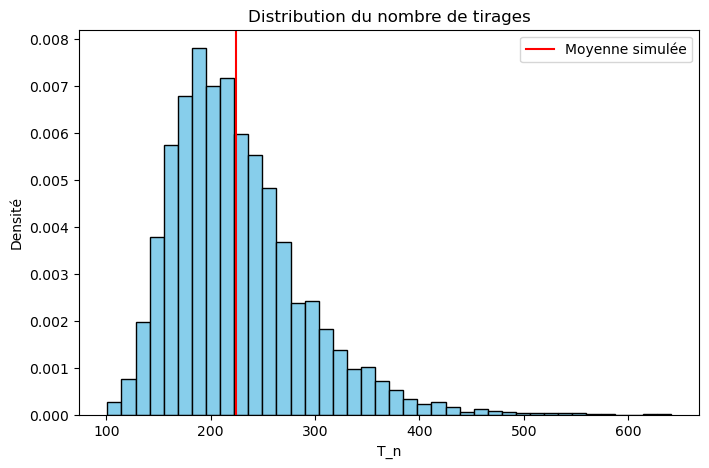

In [13]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,5))
plt.hist(samples,bins=40,density=True,color="skyblue",edgecolor="black")
plt.axvline(samples.mean(),color="red",label="Moyenne simulée")
plt.legend()
plt.title("Distribution du nombre de tirages")
plt.xlabel("T_n")
plt.ylabel("Densité")
plt.show()